# Prueba Intertrimestral

**Nombre:**  Borja
**Apellidos:**  Ibáñez Pérez

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [2]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type == "classic":
        base, rate = 1.00, 0.05
    elif bike_type == "electric":
        base, rate = 1.50, 0.08
    else:
        raise ValueError("bike_type tiene que ser 'classic' o 'electric'")
    fee = base + duration_min * rate
    if is_member:
        fee *= 0.8
    return round(fee, 2)

print(rental_fee(20, "classic", False))

2.0


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [3]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    elif total_rentals >= threshold / 2:
        return "Media"
    return "Baja"

print(demand_label(40, 40), demand_label(25, 40), demand_label(10, 40))

Alta Media Baja


c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [4]:
tripsDemo = pd.DataFrame({
    "duration_min": [12.5, 20.0, 8.5, 32.0, 15.5, 27.0, 11.0, 45.0, 18.5, 23.0],
    "bike_type": ["classic", "electric", "classic", "electric", "classic", "electric", "classic", "electric", "classic", "electric"],
    "is_member": [True, False, True, True, False, False, True, False, True, False],
    "total_rentals": [12, 42, 25, 36, 53, 18, 40, 27, 15, 60]
})
tripsDemo["fee"] = tripsDemo.apply(
    lambda row: rental_fee(row["duration_min"], row["bike_type"], row["is_member"]), axis=1
)
tripsDemo["demand"] = tripsDemo["total_rentals"].apply(lambda x: demand_label(x, 40))
tripsDemo = tripsDemo[["duration_min", "bike_type", "is_member", "fee", "total_rentals", "demand"]]
print(tripsDemo.to_string())

   duration_min bike_type  is_member   fee  total_rentals demand
0          12.5   classic       True  1.30             12   Baja
1          20.0  electric      False  3.10             42   Alta
2           8.5   classic       True  1.14             25  Media
3          32.0  electric       True  3.25             36  Media
4          15.5   classic      False  1.77             53   Alta
5          27.0  electric      False  3.66             18   Baja
6          11.0   classic       True  1.24             40   Alta
7          45.0  electric      False  5.10             27  Media
8          18.5   classic       True  1.54             15   Baja
9          23.0  electric      False  3.34             60   Alta


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [7]:
class MicromobilityTools:

    def __init__(self, duration_min, bike_type, is_member):
        self.duration_min = duration_min
        self.bike_type = bike_type
        self.is_member = is_member

    def calculate_fees(self):
        fees = []
        for i in range(len(self.duration_min)):
            fee = rental_fee(self.duration_min[i],self.bike_type[i],self.is_member[i])
            fees.append(fee)
        return fees

    def label_demand(self, total_rentals, threshold=40):
        labels = []
        for i in range(len(total_rentals)):
            label = demand_label(total_rentals[i], threshold)
            labels.append(label)
        return labels

tools = MicromobilityTools(
    tripsDemo["duration_min"].tolist(),
    tripsDemo["bike_type"].tolist(),
    tripsDemo["is_member"].tolist())

print("Tarifas:", tools.calculate_fees())
print("Demanda:", tools.label_demand(tripsDemo.total_rentals, 40))

Tarifas: [1.3, 3.1, 1.14, 3.25, 1.77, 3.66, 1.24, 5.1, 1.54, 3.34]
Demanda: ['Baja', 'Alta', 'Media', 'Media', 'Alta', 'Baja', 'Alta', 'Media', 'Baja', 'Alta']


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [8]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv", parse_dates=["datetime"])
print(mobilityData.head())
print("Filas y columnas:", mobilityData.shape)

             datetime  year  month  day  hour  weekday  season  is_holiday  \
0 2025-01-01 00:00:00  2025      1    1     0        2  Winter           1   
1 2025-01-01 01:00:00  2025      1    1     1        2  Winter           1   
2 2025-01-01 02:00:00  2025      1    1     2        2  Winter           1   
3 2025-01-01 03:00:00  2025      1    1     3        2  Winter           1   
4 2025-01-01 04:00:00  2025      1    1     4        2  Winter           1   

   is_weekend  is_workingday  ... wind_kmh  precip_mm  casual_users  \
0           0              0  ...      9.7        0.0             2   
1           0              0  ...      2.8        0.0             1   
2           0              0  ...      9.0        0.0             1   
3           0              0  ...      5.4        0.0             2   
4           0              0  ...      2.4        0.0             1   

   member_users  total_rentals  avg_trip_min  avg_distance_km  electric_share  \
0             8        

b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [9]:
def describeData(dataFrame):
    return pd.DataFrame({
        "dtype": dataFrame.dtypes.astype(str),
        "null_count": dataFrame.isnull().sum(),
        "null_pct": (dataFrame.isnull().mean() * 100).round(2)
    })

describeData(mobilityData)

,dtype,null_count,null_pct
datetime,datetime64[us],0,0.00
year,int64,0,0.00
month,int64,0,0.00
day,int64,0,0.00
hour,int64,0,0.00
weekday,int64,0,0.00
season,str,0,0.00
is_holiday,int64,0,0.00
is_weekend,int64,0,0.00
is_workingday,int64,0,0.00


c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [10]:
dataDescription = describeData(mobilityData)
print(dataDescription)
most_missing = dataDescription[dataDescription.null_count > 0].sort_values("null_pct", ascending=False)
print("\nVariables con nulos:")
print(most_missing[["null_count", "null_pct"]])

                          dtype  null_count  null_pct
datetime         datetime64[us]           0      0.00
year                      int64           0      0.00
month                     int64           0      0.00
day                       int64           0      0.00
hour                      int64           0      0.00
weekday                   int64           0      0.00
season                      str           0      0.00
is_holiday                int64           0      0.00
is_weekend                int64           0      0.00
is_workingday             int64           0      0.00
weather                     str           0      0.00
temp_c                  float64           0      0.00
humidity                float64         224      1.28
wind_kmh                float64         142      0.81
precip_mm               float64           0      0.00
casual_users              int64           0      0.00
member_users              int64           0      0.00
total_rentals             in

Las variables avg_tri_min y humidity tienen el mayor número de valores faltantes. 
Por tanto, dado que tenemos pocos nulos, antes de modelar usaría la mediana de las predictoras numéricas para evitar fuga de datos.

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


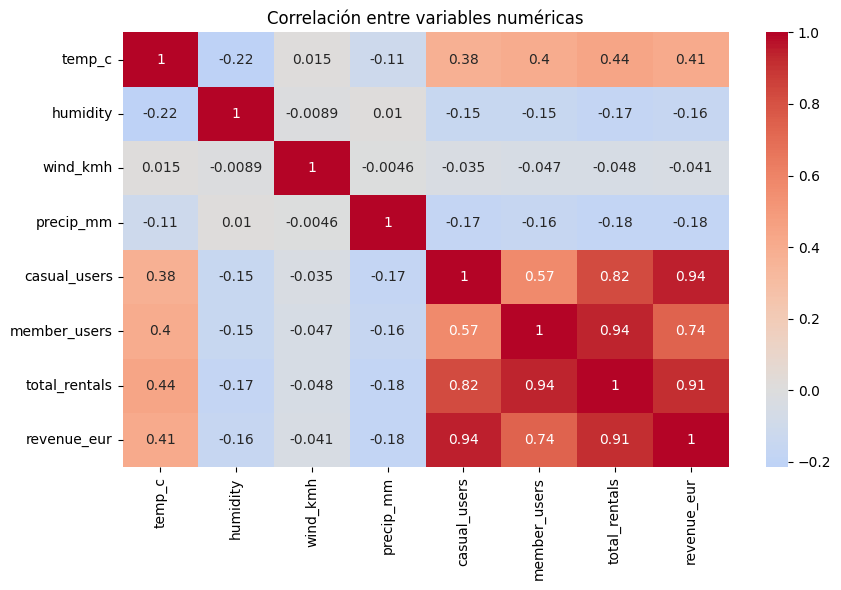

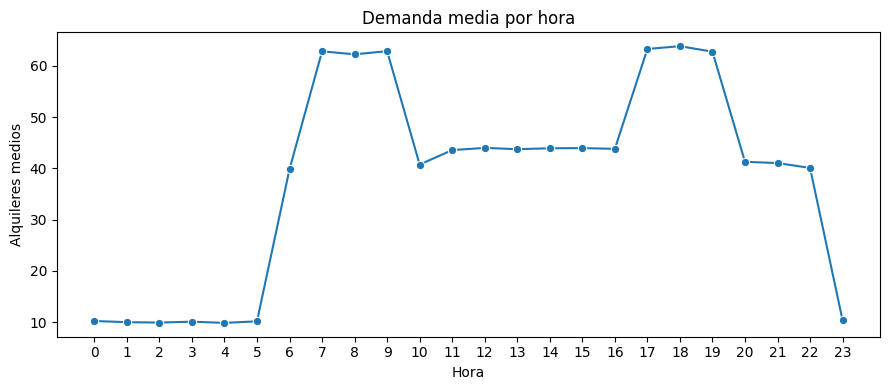

In [11]:
corr_cols = ["temp_c", "humidity", "wind_kmh", "precip_mm", "casual_users", "member_users", "total_rentals", "revenue_eur"]
plt.figure(figsize=(9, 6))
sns.heatmap(mobilityData[corr_cols].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

hourly_demand = mobilityData.groupby("hour")["total_rentals"].mean()
plt.figure(figsize=(9, 4))
sns.lineplot(x=hourly_demand.index, y=hourly_demand.values, marker="o")
plt.xticks(range(24))
plt.xlabel("Hora")
plt.ylabel("Alquileres medios")
plt.title("Demanda media por hora")
plt.tight_layout()
plt.show()

Los alquileres tienen una gran correlación con el abandono (0,94) y ocasionales (0,82).
La temperatura podemos ver que se asocia de manera positiva con la demanda (0,44). En cambio, esta úlltima se asocia de manera negativa con la lluvia (-0,18).
Los principales horarios pico los encontramos entre las 7-9 y entre las 17-19.

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [12]:
targetVar = "total_rentals"
predictors = ["hour", "temp_c", "precip_mm", "is_workingday", "month"]
X = mobilityData[predictors]
y = mobilityData[targetVar]
print("X:", X.shape, "y:", y.shape)

X: (17520, 5) y: (17520,)


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (12264, 5) Test: (5256, 5)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [14]:
linearModel = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
linearModel.fit(X_train, y_train)
linearPred = linearModel.predict(X_test)
linearR2 = r2_score(y_test, linearPred)
linearMSE = mean_squared_error(y_test, linearPred)
print(f"Regresión lineal: R2 = {linearR2}; MSE = {linearMSE}")

Regresión lineal: R2 = 0.3138779150893335; MSE = 412.7081340543377


La regresión lineal no tiene un ajuste muy bueno obteniendo un R cuadrado de 0,314 aproximadamente con un error cuadrático medio de 412,71. Con estos datos, podemos decir que apenas llega a explicarnos un tercio de la variabilidad de los alquileres.

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [15]:
forestModel = make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
forestModel.fit(X_train, y_train)
forestPred = forestModel.predict(X_test)
forestR2 = r2_score(y_test, forestPred)
forestMSE = mean_squared_error(y_test, forestPred)
print(f"Random Forest: R2 = {forestR2}; MSE = {forestMSE}")

Random Forest: R2 = 0.8952528461666467; MSE = 63.00628322100214


Comparando el resultado de la R2, vemos que Random Forest funciona mucho mejor.
El mejor modelo es Random Forest ya que permite capturar relaciones no lineales, como podrían ser los picos horarios, y también  interacciones más complicadas entre variables como temperaturas o las diferencias entre días laborables o no.

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [16]:
print(mobilityData["high_demand"].value_counts())
print((mobilityData["high_demand"].value_counts(normalize=True) * 100).round(2))

high_demand
0    12071
1     5449
Name: count, dtype: int64
high_demand
0    68.9
1    31.1
Name: proportion, dtype: float64


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [17]:
classFeatures = ["hour", "month", "temp_c", "humidity", "wind_kmh", "precip_mm", "is_workingday", "is_weekend", "is_holiday"]
X_class = mobilityData[classFeatures]
y_class = mobilityData["high_demand"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class, y_class, test_size=0.30, random_state=42, stratify=y_class
)
logisticModel = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
logisticModel.fit(Xc_train, yc_train)
yc_pred = logisticModel.predict(Xc_test)

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Accuracy: 0.7536149162861492
Matriz de confusión:
 [[3258  363]
 [ 932  703]]


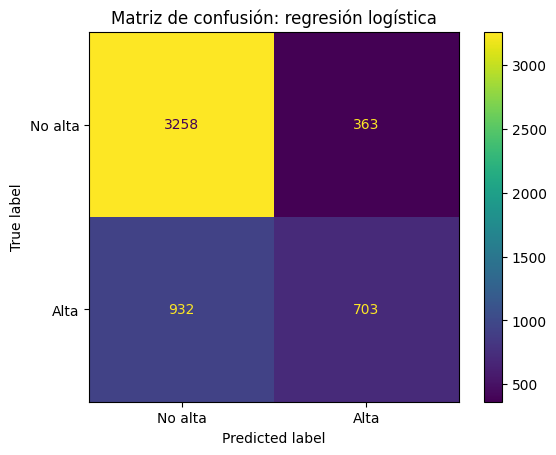

In [18]:
accuracy = accuracy_score(yc_test, yc_pred)
print(f"Accuracy: {accuracy}")
print("Matriz de confusión:\n", confusion_matrix(yc_test, yc_pred))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, display_labels=["No alta", "Alta"])
plt.title("Matriz de confusión: regresión logística")
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


In [19]:
coefficients = pd.Series(logisticModel.named_steps["logisticregression"].coef_[0], index=classFeatures)
print("Coeficientes:")
print(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).round(3).to_string())

Coeficientes:
precip_mm       -0.959
is_weekend       0.930
temp_c           0.784
is_workingday    0.701
hour             0.368
humidity        -0.247
is_holiday       0.189
wind_kmh        -0.161
month           -0.089


Fijandonos en los coeficientes que obtenemos vemos como hay una fuerte penalización por lluvia. En cuanto a la alta demanda, vemos que los factores que más importancia tienen aquí es el tipo de día, es decir, si es día laborable o no. Y también podemos ver como la temperatura tiene una fuerte relevancia.

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



El análisis realizado y el modelado de este dataset nos demuestra que la demanda de micromovilidad está principalmente guiada por tres factores: la hora, la temperatura y el tipo de día. En días laborables, encontramos que el uso responde a un patrón claramente marcado por la jornada tanto laboral como estudiantil de la gente, con picos pronunciados de uso entre las 7-9h y entre las 17-19h. En cambio, durante los fines de semana, parece que puede tener otro patrón motivado por otro tipo de uso, que podría ser una demanda más de pasatiempo. Respecto a la meteorología, vemos que las precipitaciones se asocian negativamente con el uso, algo que podíamos esperar.
Respecto al modelado predictivo, el mejor modelo concluimos que ha sido el Random Forest superando ampliamente a la regresión lineal en el cálculo de la R2 y del error. Esta superioridad tan clara seguramente se deba a las relaciones no lineales que encontramos entre algunas variables.
Como mejoras futuras, trataría de incorporar datos grandes eventos en la ciudad, huelgas o cortes de tráfico (algo tan a la orden del día ahora) o precios. Además, llevaría a cabo una validación temporal, para poder entrenar con datos histçoricos y evaluar con datos posteriores, así estaríamos en un entorno de simlación mucho más real.